# Evaluación de métodos de regresión — Estabilidad de redes eléctricas

**Aprendizaje Supervisado · Módulo 2**  
**Autor:** Raúl Pérez

Se comparan regresión lineal, regresión polinomial sin regularización, Ridge polinomial, SVR con kernel RBF y árbol de decisión para predecir `stab`. Todo el entrenamiento, la selección de hiperparámetros y la validación cruzada de 5 pliegues se realiza exclusivamente con `electrical_grid_stability_train.csv`. `electrical_grid_stability_test.csv` se reserva para la evaluación final y nunca interviene en el ajuste.

In [1]:
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler, FunctionTransformer
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

print(f'pandas version: {version("pandas")}')
print(f'scikit-learn version: {version("scikit-learn")}')
print(f'matplotlib version: {version("matplotlib")}')
print(f'numpy version: {version("numpy")}')


pandas version: 3.0.5
scikit-learn version: 1.9.1
matplotlib version: 3.10.5
numpy version: 2.3.2


In [2]:
DATA_DIR = Path.cwd()
TRAIN_PATH = DATA_DIR / "electrical_grid_stability_train.csv"
TEST_PATH = DATA_DIR / "electrical_grid_stability_test.csv"
PREDICTIONS_PATH = DATA_DIR / "predicciones_stab_test.csv"

df = pd.read_csv(TRAIN_PATH)

In [3]:
df.head() # Se obtienen todas las columnas definidas en las instrucciones

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
0,2.959060,3.079885,8.381025,9.780754,3.763085,-0.782604,-1.257395,-1.723086,0.650456,0.859578,0.887445,0.958034,0.055347
1,9.304097,4.902524,3.047541,1.369357,5.067812,-1.940058,-1.872742,-1.255012,0.413441,0.862414,0.562139,0.781760,-0.005957
2,8.971707,8.848428,3.046479,1.214518,3.405158,-1.207456,-1.277210,-0.920492,0.163041,0.766689,0.839444,0.109853,0.003471
3,0.716415,7.669600,4.486641,2.340563,3.963791,-1.027473,-1.938944,-0.997374,0.446209,0.976744,0.929381,0.362718,0.028871
4,6.999209,9.109247,3.784066,4.267788,4.429669,-1.857139,-0.670397,-1.902133,0.261793,0.077930,0.542884,0.469931,-0.017385


In [4]:
feature_cols = ["tau1", "tau2", "tau3", "tau4", "p1", "p2", "p3", "p4", "g1", "g2", "g3", "g4"]
target_col = "stab"

X = df[feature_cols].copy()
y = df[target_col].copy()
print(f"(filas,columnas): {df.shape}") # Tenemos un dataset de 8000 registros con 13 variables cada uno.

(filas,columnas): (8000, 13)


## 1. Análisis exploratorio y calidad de datos

Se revisan tipos, faltantes, duplicados, rangos, asociación lineal y observaciones señaladas por la regla exploratoria de 1.5 × IQR. Esa regla solo identifica valores para inspección: no se eliminan filas sin evidencia de errores, pues los extremos pueden ser estados válidos de la simulación.

In [5]:
df.dtypes # Todos los tipos son float64 (variables continuas)

tau1    float64
tau2    float64
tau3    float64
tau4    float64
p1      float64
p2      float64
p3      float64
p4      float64
g1      float64
g2      float64
g3      float64
g4      float64
stab    float64
dtype: object

In [6]:
df.isna().sum() # No se encuentran nulos en el dataset, por lo que no es necesario realizar imputación de datos.

tau1    0
tau2    0
tau3    0
tau4    0
p1      0
p2      0
p3      0
p4      0
g1      0
g2      0
g3      0
g4      0
stab    0
dtype: int64

In [7]:
df.duplicated().sum() # No hay duplicatos en el dataset, por lo que no es necesario limpiar duplicados.

np.int64(0)

In [8]:
df.describe().round(2) 

,tau1,tau2,tau3,tau4,p1,p2,p3,p4,g1,g2,g3,g4,stab
count,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00,8000.00
mean,5.24,5.24,5.25,5.24,3.75,-1.25,-1.25,-1.25,0.52,0.52,0.53,0.53,0.02
std,2.74,2.75,2.74,2.76,0.76,0.43,0.43,0.43,0.27,0.27,0.27,0.27,0.04
min,0.50,0.50,0.50,0.50,1.58,-2.00,-2.00,-2.00,0.05,0.05,0.05,0.05,-0.08
25%,2.87,2.84,2.88,2.86,3.22,-1.62,-1.62,-1.63,0.28,0.28,0.29,0.29,-0.02
50%,5.23,5.25,5.25,5.25,3.75,-1.25,-1.25,-1.25,0.52,0.52,0.53,0.53,0.02
75%,7.60,7.63,7.63,7.62,4.29,-0.88,-0.88,-0.88,0.76,0.76,0.76,0.77,0.04
max,10.00,10.00,10.00,10.00,5.83,-0.50,-0.50,-0.50,1.00,1.00,1.00,1.00,0.11


In [9]:
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
outlier_counts = ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum()
outlier_counts.rename("conteo").to_frame() # Solo se encuentra un posible outlier en la variable p1.

,conteo
tau1,0
tau2,0
tau3,0
tau4,0
p1,1
p2,0
p3,0
p4,0
g1,0
g2,0


In [10]:
balance_error = (df["p1"] + df["p2"] + df["p3"] + df["p4"]).abs()
print(f"\nMáximo |p1 + p2 + p3 + p4|: {balance_error.max():.2e}")
print(f"stab < 0: {(y < 0).sum():,} | stab > 0: {(y > 0).sum():,}")


Máximo |p1 + p2 + p3 + p4|: 1.00e-09
stab < 0: 2,915 | stab > 0: 5,085


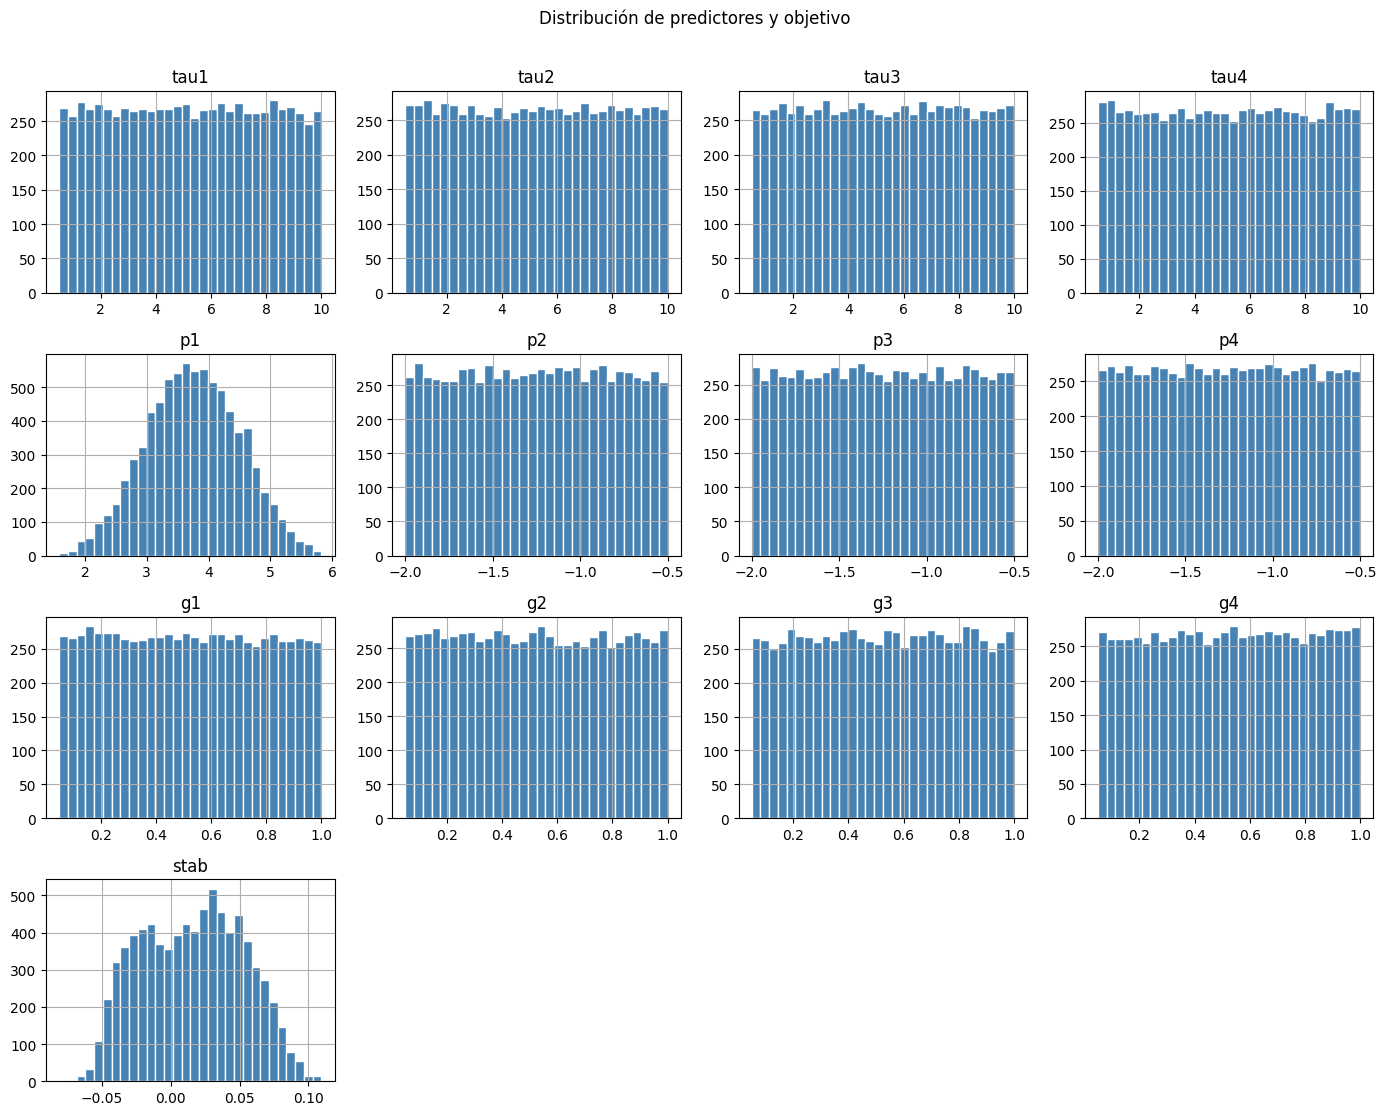

In [11]:
axes = df.hist(bins=30, figsize=(14, 11), color="steelblue", edgecolor="white")
plt.suptitle("Distribución de predictores y objetivo", y=1.01)
plt.tight_layout()
plt.show()

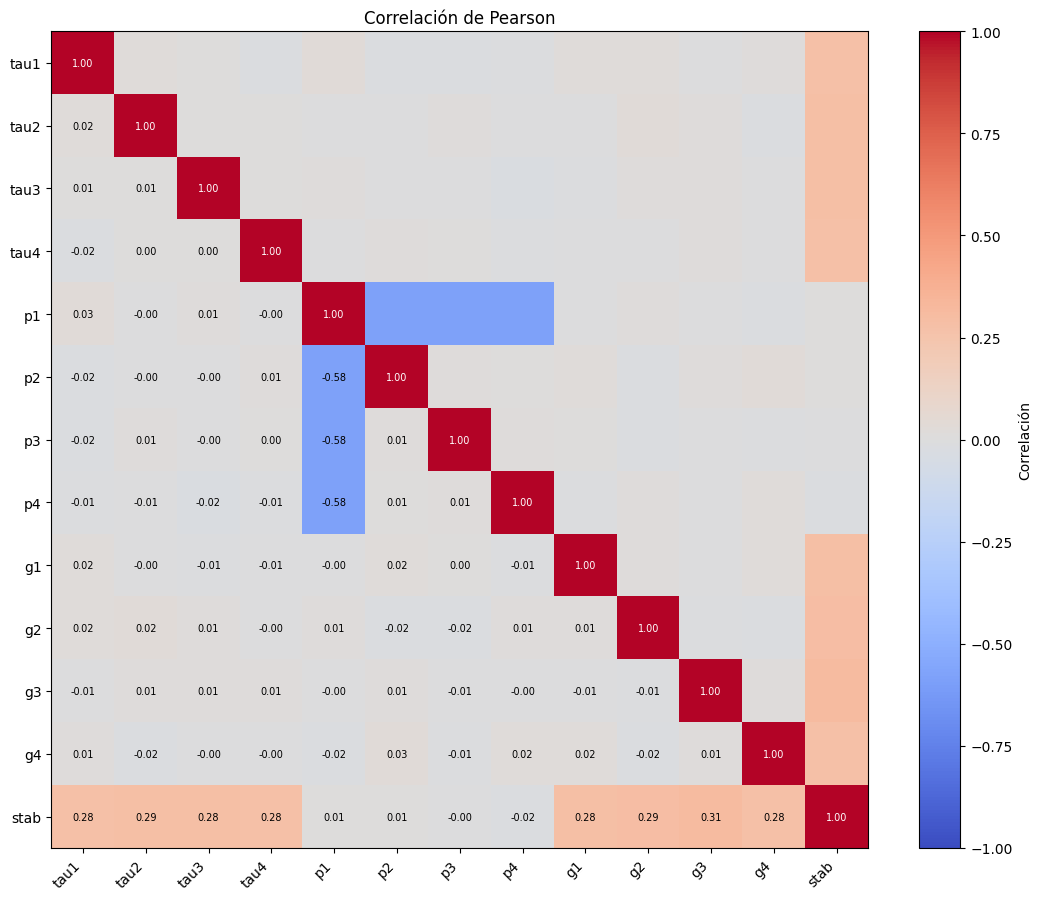

In [12]:
correlations = df.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
correlation_cols = correlations.columns.tolist()
ax.set_xticks(range(len(correlation_cols)), correlation_cols, rotation=45, ha="right")
ax.set_yticks(range(len(correlation_cols)), correlation_cols)
for i in range(len(correlations)):
        for j in range(i + 1):
            v = correlations.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
ax.set_title("Correlación de Pearson")
fig.colorbar(image, ax=ax, label="Correlación")
fig.tight_layout()
plt.show()

### Lectura e interpretación del EDA

En el archivo de entrenamiento (8,000 filas), no se observaron faltantes ni duplicados y la regla de 1.5 × IQR señaló una sola observación en `p1`; se conserva porque por sí sola no demuestra un error. El máximo error del balance de potencia fue aproximadamente `1e-9`, coherente con redondeo numérico. La mayor correlación lineal absoluta con `stab` fue cercana a 0.31 (`g3`), mientras que las potencias tuvieron correlaciones cercanas a cero. Esto motiva probar modelos no lineales, pero no demuestra causalidad ni descarta asociaciones no lineales.

## 2. Protocolo de evaluación

Se usa `KFold` de 5 pliegues, con barajado y semilla fija para reproducibilidad. RMSE es la métrica principal; también se informan MAE y R2. En las búsquedas, se selecciona la configuración por RMSE medio de los mismos cinco pliegues y se informa su media y desviación estándar.

In [13]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "rmse": "neg_root_mean_squared_error",
    "mae": "neg_mean_absolute_error",
    "r2": "r2",
}
results = []
selected_models = {}

def summarize_cv(name, scores, params=None):
    """Guarda métricas de los cinco pliegues en la orientación habitual."""
    results.append({
        "Modelo": name,
        "RMSE media": -scores["test_rmse"].mean(),
        "RMSE std": scores["test_rmse"].std(),
        "MAE media": -scores["test_mae"].mean(),
        "MAE std": scores["test_mae"].std(),
        "R2 media": scores["test_r2"].mean(),
        "R2 std": scores["test_r2"].std(),
        "Hiperparámetros": params or {},
    })

def run_search(name, estimator, param_grid):
    """Ajusta hiperparámetros y recupera las métricas por pliegue del ganador."""
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring=scoring,
        refit="rmse",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
    )
    search.fit(X, y)
    index = search.best_index_
    fold_scores = {
        "test_rmse": np.array([search.cv_results_[f"split{i}_test_rmse"][index] for i in range(cv.get_n_splits())]),
        "test_mae": np.array([search.cv_results_[f"split{i}_test_mae"][index] for i in range(cv.get_n_splits())]),
        "test_r2": np.array([search.cv_results_[f"split{i}_test_r2"][index] for i in range(cv.get_n_splits())]),
    }
    summarize_cv(name, fold_scores, search.best_params_)
    return search.best_estimator_, search.best_params_


## Seleccion de variables
Para evitar la inestabilidad en los modelos dada la multicolinealidad en las variables p1,p2,p3 y p4, considerando tambien que tienen correlación practicamente nula con la variable objetivo stab, consideraremos ajustar modelos ignorando las potencias generadas. No sin antes proponer variables construidas como el tiempo de reaccion promedio (la media de las tau) y la elasticidad total (la suma de las g), pues podrían aportar información relevante a los modelos.

In [14]:
feature_cols = ["tau1", "tau2", "tau3", "tau4", "g1", "g2", "g3", "g4"]
X = df[feature_cols].copy()

def agrega_variables (df):
    df = df.copy ()
    df ["tau_mean"] = df[["tau1", "tau2", "tau3", "tau4"]].mean(axis=1) # tiempo de reaccion promedio
    df ["g_sum"] = df[["g1", "g2", "g3", "g4"]].sum(axis=1) # elasticidad total
    return df

crea = FunctionTransformer (agrega_variables) # lo envuelve como un paso del Pipeline

## 3. Regresión lineal y polinomial sin regularización

La regresión lineal se evalúa como referencia. En la regresión polinomial se exploran grados 2 y 3; la expansión y el escalado se incluyen en el `Pipeline`, de modo que cada pliegue aprende las transformaciones únicamente con su subconjunto de entrenamiento.

In [15]:
linear_model = make_pipeline(
    crea,
    StandardScaler(),
    LinearRegression())

linear_scores = cross_validate(
    linear_model, X, y, cv=cv, scoring=scoring, n_jobs=-1)

summarize_cv("Regresión lineal", linear_scores)
selected_models["Regresión lineal"] = linear_model

polynomial_models = {}
for degree in (2, 3):
    model = make_pipeline(
        crea,
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression(),
    )
    
    scores = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    name = f"Polinomial sin regularización (grado {degree})"
    summarize_cv(name, scores, {"grado": degree})
    polynomial_models[degree] = model

best_degree = min(
    (2, 3),
    key=lambda degree: next(row["RMSE media"] for row in results if row["Modelo"] == f"Polinomial sin regularización (grado {degree})"),
)
selected_models["Polinomial sin regularización"] = polynomial_models[best_degree]
print(f"\nGrado seleccionado por RMSE medio de CV: {best_degree}")


Grado seleccionado por RMSE medio de CV: 3


## 4. Regresión polinomial con regularización Ridge

Ridge penaliza los coeficientes grandes (L2), útil al crear términos polinomiales correlacionados. Se buscan el grado y `alpha`; el escalado se ajusta dentro del flujo de cada pliegue.

In [16]:
ridge_pipeline = make_pipeline(
    crea,
    PolynomialFeatures(include_bias=False),
    StandardScaler(),
    Ridge(),
)

ridge_model, ridge_params = run_search(
    "Ridge polinomial",
    ridge_pipeline,
    {
        "polynomialfeatures__degree": [2, 3],
        "ridge__alpha": [0.1, 1.0, 10.0, 100.0],
    },
)
selected_models["Ridge polinomial"] = ridge_model
print("Mejores hiperparámetros:", ridge_params)

Mejores hiperparámetros: {'polynomialfeatures__degree': 3, 'ridge__alpha': 0.1}


## 5. Support Vector Regression (SVR)

El kernel RBF modela relaciones no lineales. Se escalan las entradas dentro del `Pipeline` y se ajustan `C`, `epsilon` y `gamma` por búsqueda en rejilla.

In [17]:
svr_pipeline = make_pipeline(
    crea,
    StandardScaler(), 
    SVR(kernel="rbf"))

svr_model, svr_params = run_search(
    "SVR RBF",
    svr_pipeline,
    {
        "svr__C": [1, 10],
        "svr__epsilon": [0.01, 0.1],
        "svr__gamma": ["scale", 0.1],
    },
)

selected_models["SVR RBF"] = svr_model
print("Mejores hiperparámetros:", svr_params)

Mejores hiperparámetros: {'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamma': 'scale'}


## 6. Árbol de decisión para regresión

Se limitan profundidad y tamaño mínimo de hoja para reducir el sobreajuste. Los árboles no requieren escalado; la selección de los criterios de poda se hace con la misma validación cruzada.

In [18]:
tree_model, tree_params = run_search(
    "Árbol de decisión",
    DecisionTreeRegressor(random_state=42),
    {
        "max_depth": [4, 8, 12],
        "min_samples_leaf": [5, 20],
    },
)
selected_models["Árbol de decisión"] = tree_model
print("Mejores hiperparámetros:", tree_params)

Mejores hiperparámetros: {'max_depth': 12, 'min_samples_leaf': 5}


## 7. Comparación de modelos y conclusión

La tabla presenta media y desviación estándar entre los cinco pliegues. Se ordena por RMSE medio, que es la métrica principal (menor es mejor); MAE complementa el error absoluto típico y R2 resume la varianza explicada. Las variantes polinomiales de grados 2 y 3 aparecen por separado. La desviación estándar ayuda a valorar la variación entre particiones.

In [19]:
results_df = pd.DataFrame(results).sort_values("RMSE media").reset_index(drop=True)
display(results_df)

best_row = results_df.iloc[0]
print(
    f"Mejor resultado de CV: {best_row['Modelo']} \n"
    f"RMSE = {best_row['RMSE media']:.6f} : {best_row['RMSE std']:.6f}, "
    f"MAE = {best_row['MAE media']:.6f}, R2 = {best_row['R2 media']:.6f}."
)

,Modelo,RMSE media,RMSE std,MAE media,MAE std,R2 media,R2 std,Hiperparámetros
0,SVR RBF,0.007961,0.000060,0.005903,0.000076,0.953534,0.001259,"{'svr__C': 1, 'svr__epsilon': 0.01, 'svr__gamm..."
1,Ridge polinomial,0.008574,0.000194,0.005968,0.000113,0.946075,0.002905,"{'polynomialfeatures__degree': 3, 'ridge__alph..."
2,Polinomial sin regularización (grado 3),0.008575,0.000195,0.005970,0.000114,0.946063,0.002913,{'grado': 3}
3,Polinomial sin regularización (grado 2),0.012306,0.000120,0.009263,0.000112,0.888962,0.003680,{'grado': 2}
4,Árbol de decisión,0.018211,0.000386,0.014049,0.000329,0.756629,0.014638,"{'max_depth': 12, 'min_samples_leaf': 5}"
5,Regresión lineal,0.022080,0.000479,0.017530,0.000455,0.642464,0.017763,{}


Mejor resultado de CV: SVR RBF 
RMSE = 0.007961 : 0.000060, MAE = 0.005903, R2 = 0.953534.


### Interpretación y límites de la comparación

Se define como mejor modelo el SVR RBF con parámetros C=1, Epsilon = 0.01 y gamma = 0.1, el cual, da como resultado un R^2 medio de 0.9535, los modelos polinomiales también obtienen resultados favorables. Esto indica que, como suponíamos, el problema necesita un modelo no lineal.

## 8. Evaluación independiente y predicciones finales

Las configuraciones se seleccionan únicamente mediante CV dentro de `electrical_grid_stability_train.csv`. Después, cada configuración se reajusta con todas las filas etiquetadas de ese archivo y predice `electrical_grid_stability_test.csv`. Si el test incluye `stab`, se reportan RMSE, MAE y R2; si no incluye etiquetas, se guardan las predicciones en `predicciones_stab_test.csv`, pero no se calculan métricas que requieren valores reales.

In [20]:
df_test = pd.read_csv(TEST_PATH) if TEST_PATH.is_file() else None

X_test = df_test[feature_cols].copy() if df_test is not None else None
y_test = df_test[target_col].copy() if df_test is not None and target_col in df_test.columns else None

if X_test is None:
    print(
        "No hay conjunto de prueba disponible. Coloca electrical_grid_stability_test.csv "
        "junto al notebook para generar la evaluación final. El entrenamiento y la CV ya se realizaron solo con electrical_grid_stability_train.csv."
    )
else:
    prediction_frame = pd.DataFrame(index=X_test.index)
    test_metrics = []
    for model_name, estimator in selected_models.items():
        fitted_model = clone(estimator).fit(X, y)
        prediction = fitted_model.predict(X_test)
        prediction_frame[f"stab_pred_{model_name}"] = prediction
        if y_test is not None:
            test_metrics.append({
                "Modelo": model_name,
                "RMSE test": mean_squared_error(y_test, prediction) ** 0.5,
                "MAE test": mean_absolute_error(y_test, prediction),
                "R2 test": r2_score(y_test, prediction),
            })

    prediction_frame.to_csv(PREDICTIONS_PATH, index=False)
    print(f"Predicciones guardadas en: {PREDICTIONS_PATH}")
    if y_test is not None:
        test_metrics_df = pd.DataFrame(test_metrics).sort_values("RMSE test").reset_index(drop=True)
        display(test_metrics_df)
        print("Estas métricas son una evaluación final; no deben usarse para volver a ajustar hiperparámetros.")
    else:
        print(
            f"El archivo de prueba no contiene '{target_col}'; RMSE, MAE y R2 reales no son calculables. "
            "No se fabrican métricas a partir de predicciones sin etiquetas."
        )

Predicciones guardadas en: c:\Users\raul.perez\Documents\MIA\Github\MIA_Raul_P\Aprendizaje_supervisado\modulo2\predicciones_stab_test.csv
El archivo de prueba no contiene 'stab'; RMSE, MAE y R2 reales no son calculables. No se fabrican métricas a partir de predicciones sin etiquetas.
